посмотрим, на каких почасовых рядах модель chronos-2 проигрывает сезонному наивному прогнозу

In [1]:
!pip install -q "chronos-forecasting>=2.0" gluonts

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from gluonts.dataset.repository import get_dataset
from chronos import BaseChronosPipeline

414 почасовых рядов M4 (последение 48 часов - тест)

In [3]:
ds = get_dataset("m4_hourly")
series = [entry["target"] for entry in ds.test]

/usr/local/lib/python3.13/dist-packages/gluonts/dataset/common.py:263: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return pd.Period(val, freq)


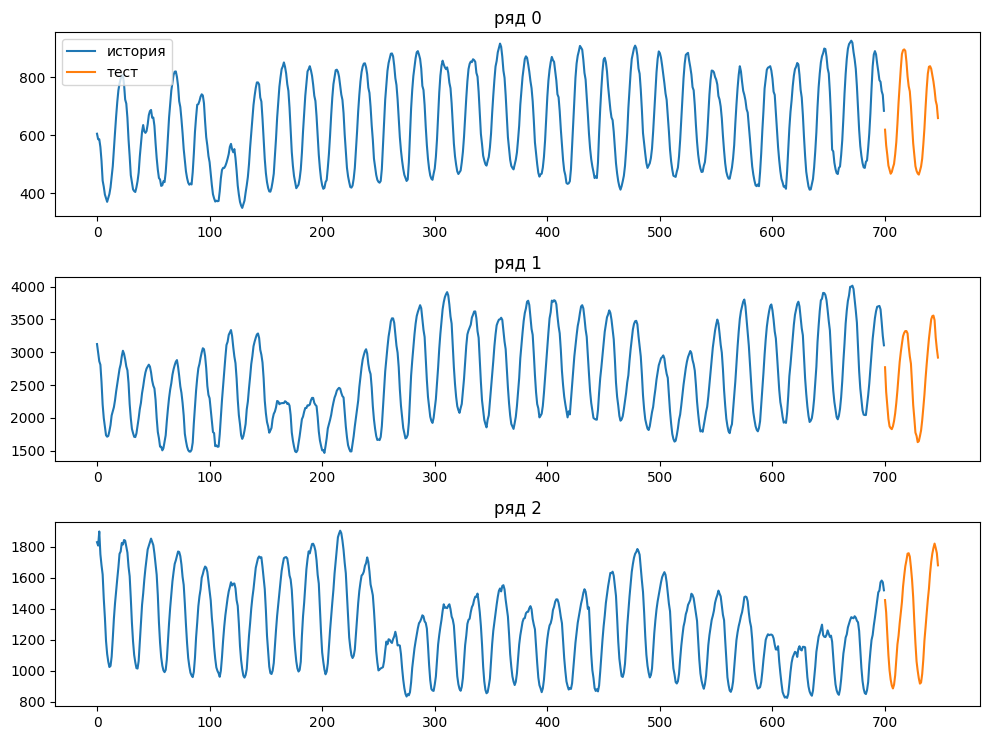

In [4]:
def plot_series(series, ids, horizon=48):
    fig, axes = plt.subplots(len(ids), 1, figsize=(10, 2.5 * len(ids)))
    for ax, i in zip(axes, ids):
        y = series[i]
        ax.plot(range(len(y) - horizon), y[:-horizon], label="история")
        ax.plot(range(len(y) - horizon, len(y)), y[-horizon:], label="тест")
        ax.set_title(f"ряд {i}")
    axes[0].legend()
    plt.tight_layout()
    plt.show()


plot_series(series, [0, 1, 2])

наивный прогноз повторяет последние сутки, mase - ошибка прогноза, делённая на ошибку сезонного наивного внутри истории

In [5]:
#посмотрим на наивный сезонный

def seasonal_naive(history, horizon, season):
  last_season = history[-season:]
  k = int(np.ceil(horizon/season))
  return np.tile(last_season, k)[:horizon]


def mase(actual, forecast, history, season):
  mae = np.mean(np.abs(actual-forecast))
  mean_naive = np.mean(np.abs(history[season:]-history[:-season]))
  return mae / mean_naive

In [6]:
naive_mase = []
season = 24
horizon = 48
for y in series:
  history = y[:-horizon]
  actual = y[-horizon:]
  forecast = seasonal_naive(history, horizon, season)
  naive_mase.append(mase(actual, forecast, history, season))

In [7]:
np.mean(naive_mase), np.median(naive_mase)

(np.float32(1.1932102), np.float32(1.1273565))

mase наивного около единицы, значит метрика считается корректно

теперь посмотрим на chronos-2, предобученная модель без дообучения, для mase берём медиану прогноза

In [8]:
pipeline = BaseChronosPipeline.from_pretrained("autogluon/chronos-2", device_map="cpu")

def chronos_forecast(history, horizon):
  timestamp = pd.date_range("2026-10-21", periods=len(history), freq="h")
  data = pd.DataFrame({"item_id":"s", "timestamp":timestamp, "target":history})
  pred = pipeline.predict_df(data, prediction_length=horizon, quantile_levels=[0.5])
  return pred["0.5"].to_numpy()

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

In [9]:
chronos_mase = []
for y in series:
  history = y[:-horizon]
  actual = y[-horizon:]
  forecast = chronos_forecast(history, horizon)
  chronos_mase.append(mase(actual, forecast, history, season))

In [10]:
np.mean(chronos_mase), np.median(chronos_mase)

(np.float32(0.8105862), np.float32(0.6729138))

cредний mase chronos-2 примерно на треть меньше чем у наивного

делим ряды на две группы, где mase chronos-2 меньше, чем у наивного, и где больше

In [11]:
win_chronos = [series[i] for i in range(len(series)) if chronos_mase[i] < naive_mase[i]]
lose_chronos = [series[i] for i in range(len(series)) if chronos_mase[i] >= naive_mase[i]]

In [12]:
len(win_chronos), len(lose_chronos), round(len(lose_chronos)/(len(lose_chronos)+len(win_chronos)), 3)

(332, 82, 0.198)

chronos-2 проигрывает на 82 рядах из 414 (около 20%)

сравним группы по силе сезонности, силе тренда и стабильности суточного профиля, признаки считаются только по истории

In [13]:
from statsmodels.tsa.seasonal import STL
from scipy.stats import mannwhitneyu

def series_features(y, season=24, horizon=48):
    history = np.asarray(y[:-horizon], dtype=float)
    res = STL(history, period=season).fit()
    trend, seas, resid = res.trend, res.seasonal, res.resid
    seasonal_strength = max(0, 1 - np.var(resid) / np.var(seas + resid))
    trend_strength = max(0, 1 - np.var(resid) / np.var(trend + resid))
    stability = np.corrcoef(history[-season:], history[-2*season:-season])[0, 1]
    return {"seasonal_strength": seasonal_strength,
            "trend_strength": trend_strength,
            "stability": stability}
win_fr = pd.DataFrame([series_features(y) for y in win_chronos])
lose_fr = pd.DataFrame([series_features(y) for y in lose_chronos])
print(pd.DataFrame({"Chronos выиграла": win_fr.median(),
                    "Chronos проиграла": lose_fr.median()}).round(3))
for col in win_fr.columns:
    p = mannwhitneyu(win_fr[col], lose_fr[col]).pvalue
    print(f"{col}: p = {p:.4f}")

                   Chronos выиграла  Chronos проиграла
seasonal_strength             0.977              0.994
trend_strength                0.889              0.940
stability                     0.985              0.998
seasonal_strength: p = 0.0069
trend_strength: p = 0.0531
stability: p = 0.0042


проигрышные ряды сильнее и стабильнее по сезонности (p < 0.01), по тренду различие незначимо

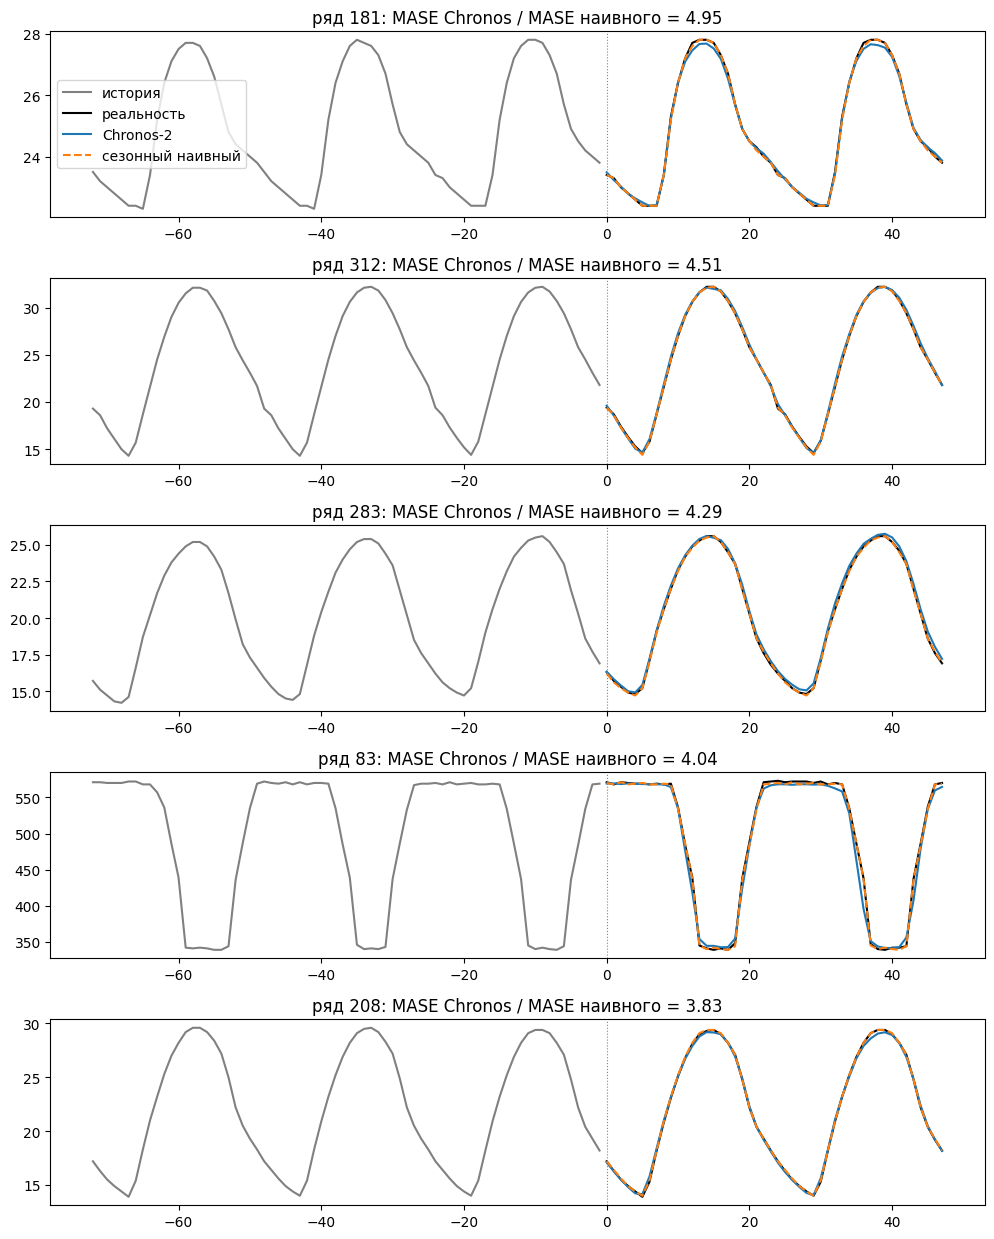

In [14]:
results = pd.DataFrame({"naive": naive_mase, "chronos": chronos_mase})
ratio = results["chronos"] / results["naive"]

def plot_forecasts(series, ids, horizon=48, season=24, tail=72):
    fig, axes = plt.subplots(len(ids), 1, figsize=(10, 2.5 * len(ids)))
    for ax, i in zip(axes, ids):
        y = series[i]
        history, actual = y[:-horizon], y[-horizon:]

        x_hist = range(-tail, 0)
        x_test = range(0, horizon)

        ax.plot(x_hist, history[-tail:], color="gray", label="история")
        ax.plot(x_test, actual, color="black", label="реальность")
        ax.plot(x_test, chronos_forecast(history, horizon), label="Chronos-2")
        ax.plot(x_test, seasonal_naive(history, horizon, season), "--", label="сезонный наивный")
        ax.axvline(0, color="gray", lw=0.8, ls=":")
        ax.set_title(f"ряд {i}: MASE Chronos / MASE наивного = {ratio[i]:.2f}")
    axes[0].legend()
    plt.tight_layout()
    plt.show()

worst = ratio.sort_values(ascending=False).index[:5]
plot_forecasts(series, worst)

на этих рядах суточный профиль повторяется почти без изменений: сезонный наивный почти идеален, а chronos-2 слегка сглаживает пики